In [1]:
import os
os.environ['OMP_NUM_THREADS'] = '1'

### Step 1: Import Required Libraries

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [3]:
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

In [4]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split

In [5]:
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, classification_report, roc_auc_score)

---

### Step 2: Create the Dataset

In [6]:
data = {
    'MachineTemperature': [
        65, 70, 85, 90, 60, 95, 75, 100, 68, 88,
        105, 72, 80, 110, 63, 98, 78, 115, 67, 92,
        82, 108, 73, 102, 69, 87, 118, 76, 96, 64
    ],

    'OperatingHours': [
        1200, 1500, 3000, 3500, 900, 4000, 1800, 4500, 1300, 3200,
        5000, 1600, 2500, 5500, 1000, 4200, 2100, 6000, 1100, 3800,
        2800, 5200, 1700, 4800, 1250, 3100, 6500, 1900, 4300, 950
    ],

    'VibrationLevel': [
        2.1, 2.5, 5.8, 6.2, 1.8, 7.1, 3.0, 8.0, 2.3, 6.0,
        8.5, 2.8, 4.2, 9.0, 1.9, 7.5, 3.5, 9.5, 2.0, 6.8,
        4.8, 8.8, 2.9, 8.2, 2.2, 5.9, 9.8, 3.2, 7.3, 1.7
    ],

    'RotationalSpeed': [
        1500, 1450, 1300, 1250, 1550, 1200, 1400, 1150, 1520, 1280,
        1100, 1480, 1350, 1050, 1580, 1180, 1380, 1000, 1560, 1220,
        1320, 1080, 1470, 1120, 1540, 1290, 980, 1420, 1160, 1570
    ],

    'PressureLevel': [
        30, 32, 45, 48, 28, 52, 35, 58, 31, 46,
        60, 33, 40, 65, 29, 55, 36, 70, 30, 50,
        42, 62, 34, 59, 31, 47, 72, 37, 54, 28
    ],

    'MaintenanceFrequency': [
        2, 2, 5, 6, 1, 7, 3, 8, 2, 5,
        9, 2, 4, 10, 1, 8, 3, 11, 1, 6,
        4, 9, 2, 8, 1, 5, 12, 3, 7, 1
    ],

    'MachineAge': [
        2, 3, 7, 8, 1, 9, 4, 10, 2, 7,
        11, 3, 5, 12, 1, 10, 4, 13, 1, 8,
        6, 11, 3, 10, 2, 7, 14, 4, 9, 1
    ],

    'PowerConsumption': [
        20, 22, 35, 38, 18, 42, 25, 45, 21, 37,
        48, 23, 30, 52, 19, 44, 26, 55, 20, 40,
        32, 50, 24, 47, 21, 36, 58, 27, 43, 18
    ],

    'MachineFailure': [
        0, 0, 1, 1, 0, 1, 0, 1, 0, 1,
        1, 0, 0, 1, 0, 1, 0, 1, 0, 1,
        0, 1, 0, 1, 0, 1, 1, 0, 1, 0
    ]
}

df = pd.DataFrame(data)
df.head()

,MachineTemperature,OperatingHours,VibrationLevel,RotationalSpeed,PressureLevel,MaintenanceFrequency,MachineAge,PowerConsumption,MachineFailure
0,65,1200,2.1,1500,30,2,2,20,0
1,70,1500,2.5,1450,32,2,3,22,0
2,85,3000,5.8,1300,45,5,7,35,1
3,90,3500,6.2,1250,48,6,8,38,1
4,60,900,1.8,1550,28,1,1,18,0


In [7]:
# Check the dataset:

print("Dataset Shape:", df.shape)

print("\nDataset Information:")
print(df.info())

print("\nTarget Distribution:")
print(df['MachineFailure'].value_counts())

Dataset Shape: (30, 9)

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 30 entries, 0 to 29
Data columns (total 9 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   MachineTemperature    30 non-null     int64  
 1   OperatingHours        30 non-null     int64  
 2   VibrationLevel        30 non-null     float64
 3   RotationalSpeed       30 non-null     int64  
 4   PressureLevel         30 non-null     int64  
 5   MaintenanceFrequency  30 non-null     int64  
 6   MachineAge            30 non-null     int64  
 7   PowerConsumption      30 non-null     int64  
 8   MachineFailure        30 non-null     int64  
dtypes: float64(1), int64(8)
memory usage: 2.2 KB
None

Target Distribution:
MachineFailure
0    15
1    15
Name: count, dtype: int64


---

### Step 3: Handle Missing Values and Duplicate Records

In [8]:
# Check duplicate records

print("Duplicate Records:", df.duplicated().sum())

Duplicate Records: 0


In [9]:
# Remove duplicate records

df = df.drop_duplicates().copy()

In [10]:
# Separate features and target

X = df.drop('MachineFailure', axis=1)

y = df['MachineFailure']

In [11]:
# Handle missing values

imputer = SimpleImputer(strategy='median')

X_imputed = pd.DataFrame(imputer.fit_transform(X), columns=X.columns, index=X.index)

print("\nMissing Values After Imputation:")
print(X_imputed.isnull().sum())


Missing Values After Imputation:
MachineTemperature      0
OperatingHours          0
VibrationLevel          0
RotationalSpeed         0
PressureLevel           0
MaintenanceFrequency    0
MachineAge              0
PowerConsumption        0
dtype: int64


---

### Step 4: Split the Dataset

In [12]:
X_train, X_test, y_train, y_test = train_test_split(X_imputed, y, test_size=0.2, random_state=42, stratify=y)

---

### Step 5: Apply Feature Scaling

In [13]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)

X_test_scaled = scaler.transform(X_test)

---

### Step 6: Apply K-Means Clustering

In [14]:
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)

train_clusters = kmeans.fit_predict(X_train_scaled)

test_clusters = kmeans.predict(X_test_scaled)

print("Training Clusters:")
print(train_clusters)

print("\nTesting Clusters:")
print(test_clusters)

Training Clusters:
[0 2 0 0 0 0 2 2 0 2 0 0 0 1 0 1 2 1 2 0 1 2 1 1]

Testing Clusters:
[2 1 1 0 1 0]


---

### Step 7: Add Cluster Labels to the Dataset

In [15]:
X_train_hybrid = X_train.copy()

X_test_hybrid = X_test.copy()

X_train_hybrid['MachineCluster'] = train_clusters

X_test_hybrid['MachineCluster'] = test_clusters

X_train_hybrid.head()

,MachineTemperature,OperatingHours,VibrationLevel,RotationalSpeed,PressureLevel,MaintenanceFrequency,MachineAge,PowerConsumption,MachineCluster
16,78.0,2100.0,3.5,1380.0,36.0,3.0,4.0,26.0,0
23,102.0,4800.0,8.2,1120.0,59.0,8.0,10.0,47.0,2
22,73.0,1700.0,2.9,1470.0,34.0,2.0,3.0,24.0,0
1,70.0,1500.0,2.5,1450.0,32.0,2.0,3.0,22.0,0
18,67.0,1100.0,2.0,1560.0,30.0,1.0,1.0,20.0,0


---

### Step 8: Train Random Forest Classifier

In [16]:
model = RandomForestClassifier(n_estimators=200, max_depth=6, class_weight='balanced', random_state=42)

model.fit(X_train_hybrid, y_train)

print("Random Forest Model Training Completed!")

Random Forest Model Training Completed!


---

### Step 9: Evaluate Model Performance

In [17]:
y_pred = model.predict(X_test_hybrid)
y_prob = model.predict_proba(X_test_hybrid)[:, 1]

accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred, zero_division=0)
recall = recall_score(y_test, y_pred, zero_division=0)
f1 = f1_score(y_test, y_pred, zero_division=0)
roc_auc = roc_auc_score(y_test, y_prob)

print("Accuracy:", accuracy)
print("Precision:", precision)
print("Recall:", recall)
print("F1 Score:", f1)
print("ROC-AUC:", roc_auc)

Accuracy: 1.0
Precision: 1.0
Recall: 1.0
F1 Score: 1.0
ROC-AUC: 1.0


---

### Step 10: Display Confusion Matrix

In [18]:
cm = confusion_matrix(y_test, y_pred)

print("Confusion Matrix:")
print(cm)

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

Confusion Matrix:
[[3 0]
 [0 3]]

Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00         3
           1       1.00      1.00      1.00         3

    accuracy                           1.00         6
   macro avg       1.00      1.00      1.00         6
weighted avg       1.00      1.00      1.00         6



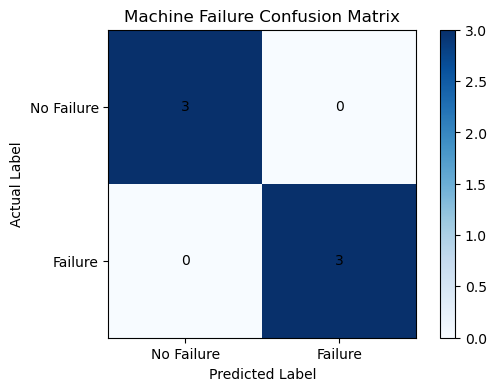

In [19]:
# Visualize the confusion matrix:

plt.figure(figsize=(6, 4))
plt.imshow(cm, cmap='Blues')
plt.title("Machine Failure Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.xticks([0, 1], ['No Failure', 'Failure'])
plt.yticks([0, 1], ['No Failure', 'Failure'])

for i in range(2):
    for j in range(2):
        plt.text(j, i, cm[i, j], ha='center', va='center')

plt.colorbar()
plt.show()

---

### Step 11: Identify Important Failure Indicators

In [21]:
importance = pd.DataFrame({'Feature': X_train_hybrid.columns, 'Importance': model.feature_importances_})
importance = importance.sort_values(by='Importance', ascending=False)

In [22]:
importance

,Feature,Importance
0,MachineTemperature,0.180
1,OperatingHours,0.175
7,PowerConsumption,0.130
2,VibrationLevel,0.115
3,RotationalSpeed,0.115
5,MaintenanceFrequency,0.095
6,MachineAge,0.085
4,PressureLevel,0.075
8,MachineCluster,0.030
